In [1]:
import warnings
warnings.filterwarnings("ignore")

In [2]:
from IPython.display import display
import pandas as pd
import time
import matplotlib.pyplot as plt
from mlxtend.frequent_patterns import apriori, fpgrowth

##ĐỌC FILE TỪ THÀNH VIÊN 1
url = "https://raw.githubusercontent.com/KhoaDuong69/Data_Mining_Project/main/Data_Mining_Project/THKTDL/Data/food_association_ready.csv"

df_encoded = pd.read_csv(url)

print("Số sinh viên (transactions):", len(df_encoded))
print("Số item:", len(df_encoded.columns))
display(df_encoded.head())

Số sinh viên (transactions): 125
Số item: 37


,breakfast_Breakfast_No,breakfast_Breakfast_Yes,eating_out_High,eating_out_Low,eating_out_Medium,fruit_day_High,fruit_day_Low,fruit_day_Medium,veggies_day_High,veggies_day_Low,...,greek_food_Medium,indian_food_High,indian_food_Low,indian_food_Medium,thai_food_High,thai_food_Low,thai_food_Medium,ethnic_food_High,ethnic_food_Low,ethnic_food_Medium
0,1,0,0,0,1,1,0,0,1,0,...,0,1,0,0,0,1,0,0,1,0
1,1,0,0,1,0,0,0,1,0,0,...,1,0,0,1,0,1,0,0,0,1
2,1,0,0,1,0,1,0,0,1,0,...,0,1,0,0,1,0,0,1,0,0
3,1,0,0,1,0,0,0,1,0,0,...,0,1,0,0,1,0,0,1,0,0
4,1,0,0,1,0,0,0,1,0,0,...,1,0,1,0,0,0,1,0,0,1


 Kiểm tra dữ liệu đầu vào

 Kiểm tra giá trị thiếu, giá trị ngoài 0/1, tên cột trùng; sau đó đổi 0/1 thành False/True.

 astype(bool) có thể biến giá trị khác 0 (hoặc NaN) thành True, nên **phải kiểm tra trước khi chuyển kiểu**.

 Tránh kết quả support sai do dữ liệu lỗi. Không tự xóa các dòng khảo sát giống nhau: hai sinh viên trả lời giống nhau vẫn là hai transaction hợp lệ.

In [3]:
# Kiểm tra dữ liệu trước khi chạy Apriori

print("Số ô bị thiếu:", df_encoded.isna().sum().sum())
print("Các giá trị xuất hiện:", pd.unique(df_encoded.to_numpy().ravel()))

if df_encoded.empty:
    print("Lỗi: File không có dữ liệu!")

elif df_encoded.columns.duplicated().any():
    print("Lỗi: Tên cột bị trùng!")

elif df_encoded.isna().sum().sum() > 0:
    print("Lỗi: Dữ liệu có giá trị thiếu!")

elif not df_encoded.isin([0, 1]).all().all():
    print("Lỗi: Dữ liệu phải chỉ chứa 0 và 1!")

else:
    print("Dữ liệu hợp lệ!")

    df_encoded = df_encoded.astype(bool)

    display(df_encoded.head())

Số ô bị thiếu: 0
Các giá trị xuất hiện: [1 0]
Dữ liệu hợp lệ!


,breakfast_Breakfast_No,breakfast_Breakfast_Yes,eating_out_High,eating_out_Low,eating_out_Medium,fruit_day_High,fruit_day_Low,fruit_day_Medium,veggies_day_High,veggies_day_Low,...,greek_food_Medium,indian_food_High,indian_food_Low,indian_food_Medium,thai_food_High,thai_food_Low,thai_food_Medium,ethnic_food_High,ethnic_food_Low,ethnic_food_Medium
0,True,False,False,False,True,True,False,False,True,False,...,False,True,False,False,False,True,False,False,True,False
1,True,False,False,True,False,False,False,True,False,False,...,True,False,False,True,False,True,False,False,False,True
2,True,False,False,True,False,True,False,False,True,False,...,False,True,False,False,True,False,False,True,False,False
3,True,False,False,True,False,False,False,True,False,False,...,False,True,False,False,True,False,False,True,False,False
4,True,False,False,True,False,False,False,True,False,False,...,True,False,True,False,False,False,True,False,False,True


THUẬT TOÁN APRIORI MINSUP=0.1

 Tìm các tập item xuất hiện trong ít nhất 10% số sinh viên. use_colnames=True hiển thị tên thuộc tính thay cho mã cột.

 Nếu một tập item không phổ biến thì mọi tập chứa nó cũng không phổ biến. Nhờ vậy thuật toán loại bớt các ứng viên.

Tìm các thói quen hoặc sở thích thường xuất hiện cùng nhau và tạo đầu vào cho phần sinh luật của Thành viên 3.

Thời gian được đo bằng time.perf_counter() đặt ngay trước và sau lời gọi thuật toán.

In [4]:
from mlxtend.frequent_patterns import apriori

start_time = time.perf_counter()

frequent_itemsets_ap = apriori(
    df_encoded,
    min_support=0.1,
    use_colnames=True
)

apriori_time = time.perf_counter() - start_time

print("KẾT QUẢ Thuật Toán")
print("Min Support:", 0.1)
print("Số frequent itemsets:", len(frequent_itemsets_ap))
print("Thời gian chạy:", round(apriori_time, 6), "giây")

display(frequent_itemsets_ap)

KẾT QUẢ Thuật Toán
Min Support: 0.1
Số frequent itemsets: 2558
Thời gian chạy: 0.037257 giây


,support,itemsets
0,0.888,frozenset({breakfast_Breakfast_No})
1,0.112,frozenset({breakfast_Breakfast_Yes})
2,0.608,frozenset({eating_out_Low})
3,0.296,frozenset({eating_out_Medium})
4,0.504,frozenset({fruit_day_High})
...,...,...
2553,0.112,"frozenset({italian_food_High, fruit_day_High, ..."
2554,0.112,"frozenset({italian_food_High, healthy_feeling_..."
2555,0.120,"frozenset({indian_food_High, italian_food_High..."
2556,0.112,"frozenset({italian_food_High, fruit_day_High, ..."


Thuật toán FP-Growth cùng MinSup sử dụng cùng minsup=0.1

In [5]:
minsup = 0.1
start = time.perf_counter()
frequent_itemsets_fp = fpgrowth(df_encoded, min_support=minsup, use_colnames=True)
fpgrowth_time = time.perf_counter() - start

print("FP-Growth - số tập phổ biến:", len(frequent_itemsets_fp))
print("Thời gian (giây):", round(fpgrowth_time, 6))
display(frequent_itemsets_fp.sort_values("support", ascending=False).head(20))

FP-Growth - số tập phổ biến: 2558
Thời gian (giây): 0.084276


,support,itemsets
0,0.888,frozenset({breakfast_Breakfast_No})
1,0.800,frozenset({italian_food_High})
34,0.720,"frozenset({italian_food_High, breakfast_Breakf..."
12,0.616,frozenset({healthy_feeling_High})
13,0.608,frozenset({eating_out_Low})
807,0.560,"frozenset({healthy_feeling_High, breakfast_Bre..."
810,0.536,"frozenset({eating_out_Low, breakfast_Breakfast..."
14,0.536,frozenset({cook_Medium})
15,0.504,frozenset({nutritional_check_Medium})
16,0.504,frozenset({calories_day_Medium})


THUẬT TOÁN IT _TREE CHO NGƯỠNG MINSUP=0.1

In [6]:
def it_tree_mining(df, minsup=0.1):
    n = len(df)
    if n == 0:
        raise ValueError("Dữ liệu rỗng")

    # Lấy các giao dịch chứa từng item
    items = [
        (col, set(df.index[df[col]]))
        for col in df.columns
    ]

    results = []

    # Tìm các tập phổ biến bằng cách giao TID
    def search(prefix, items):
        for i, (name, tids) in enumerate(items):
            if len(tids) / n < minsup:
                continue

            new_set = prefix | {name}
            results.append((len(tids) / n, frozenset(new_set)))

            next_items = [
                (name2, tids & tids2)
                for name2, tids2 in items[i + 1:]
            ]

            search(new_set, next_items)

    search(set(), items)

    return pd.DataFrame(results, columns=["support", "itemsets"])


# RUN IT-Tree
start = time.perf_counter()

frequent_itemsets_it = it_tree_mining(df_encoded, 0.1)

it_time = time.perf_counter() - start

print("Số tập phổ biến:", len(frequent_itemsets_it))
print("Thời gian:", round(it_time, 6), "giây")

display(frequent_itemsets_it.head(20))

Số tập phổ biến: 2558
Thời gian: 0.025479 giây


,support,itemsets
0,0.888,frozenset({breakfast_Breakfast_No})
1,0.536,"frozenset({eating_out_Low, breakfast_Breakfast..."
2,0.288,"frozenset({fruit_day_High, eating_out_Low, bre..."
3,0.216,"frozenset({veggies_day_High, fruit_day_High, e..."
4,0.136,"frozenset({calories_day_Medium, fruit_day_High..."
5,0.120,"frozenset({calories_day_Medium, fruit_day_High..."
6,0.112,"frozenset({cook_Medium, fruit_day_High, breakf..."
7,0.128,"frozenset({fruit_day_High, healthy_feeling_Hig..."
8,0.104,"frozenset({fruit_day_High, italian_food_High, ..."
9,0.104,"frozenset({fruit_day_High, breakfast_Breakfast..."


KIỂM TRA 3 THUẬT TOÁN

In [7]:
# KIỂM TRA KẾT QUẢ 3 THUẬT TOÁN

# Lấy các tập phổ biến
ap = set(frequent_itemsets_ap["itemsets"])
fp = set(frequent_itemsets_fp["itemsets"])
it = set(frequent_itemsets_it["itemsets"])

# In số lượng tập phổ biến
print("Apriori:", len(ap))
print("FP-Growth:", len(fp))
print("IT-Tree:", len(it))

# So sánh kết quả
if ap == fp == it:
    print("3 thuật toán cho cùng tập phổ biến")
else:
    print("3 thuật toán cho kết quả khác nhau")

Apriori: 2558
FP-Growth: 2558
IT-Tree: 2558
3 thuật toán cho cùng tập phổ biến


Thực nghiệm Trục B: MinSup và thời gian chạy
 Cho cả ba thuật toán chạy với các mức MinSup 5%, 10%, 15%, 20%, 25%, 30%; lưu số tập phổ biến và thời gian.

MinSup thấp thường giữ nhiều tập phổ biến hơn.

Đo thời gian ở nhiều ngưỡng cho thấy thuật toán phản ứng thế nào khi độ khó thay đổi.

Có bảng và biểu đồ đúng yêu cầu Trục B. Mỗi cấu hình được chạy 3 lần và lấy trung vị để hạn chế dao động thời gian trên Colab;

Đồng thời do dữ liệu nhỏ nên thời gian có thể rất ngắn và không ổn định sau mỗi lần chạy.

In [8]:
# THỰC NGHIỆM MINSUP VÀ THỜI GIAN CHẠY

minsup_values = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]
results = []

for ms in minsup_values:

    # Apriori
    time_ap = []
    for i in range(3):
        start = time.perf_counter()
        ap = apriori(df_encoded, min_support=ms, use_colnames=True)
        time_ap.append(time.perf_counter() - start)

    # FP-Growth
    time_fp = []
    for i in range(3):
        start = time.perf_counter()
        fp = fpgrowth(df_encoded, min_support=ms, use_colnames=True)
        time_fp.append(time.perf_counter() - start)

    # IT-Tree
    time_it = []
    for i in range(3):
        start = time.perf_counter()
        it = it_tree_mining(df_encoded, ms)
        time_it.append(time.perf_counter() - start)

    # Lưu kết quả
    results.append({
        "MinSup": ms,
        "Apriori_Time": sorted(time_ap)[1],
        "FP_Growth_Time": sorted(time_fp)[1],
        "IT_Tree_Time": sorted(time_it)[1],
        "Apriori_Itemsets": len(ap),
        "FP_Growth_Itemsets": len(fp),
        "IT_Tree_Itemsets": len(it)
    })

experiment_df = pd.DataFrame(results)

display(experiment_df)

,MinSup,Apriori_Time,FP_Growth_Time,IT_Tree_Time,Apriori_Itemsets,FP_Growth_Itemsets,IT_Tree_Itemsets
0,0.05,0.150170,0.200113,0.048403,11618,11618,11618
1,0.10,0.032065,0.050711,0.021333,2558,2558,2558
2,0.15,0.008295,0.016526,0.010004,873,873,873
3,0.20,0.004502,0.012803,0.009918,373,373,373
4,0.25,0.005070,0.008436,0.009411,156,156,156
5,0.30,0.004303,0.007721,0.005869,90,90,90


BIỂU ĐỒ THỰC NGHIỆM


Biểu đồ MinSup và số tập phổ biến

Giải thích :Cả 3 thuật toán đều có cùng số tập phổ biến nên 3 đường trùng nhau

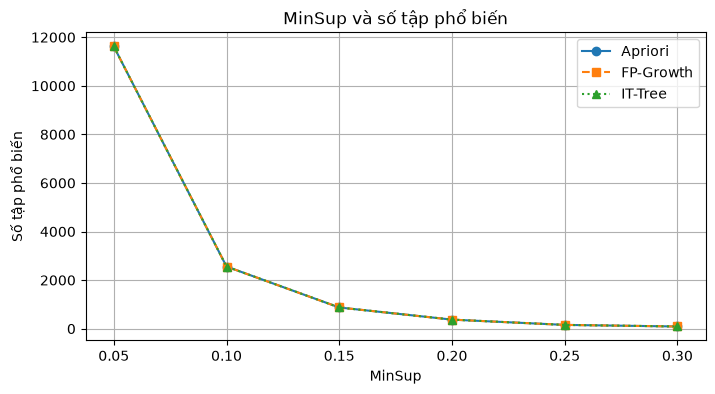

In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))

plt.plot(experiment_df["MinSup"],
         experiment_df["Apriori_Itemsets"],
         marker="o", label="Apriori")

plt.plot(experiment_df["MinSup"],
         experiment_df["FP_Growth_Itemsets"],
         marker="s", linestyle="--", label="FP-Growth")

plt.plot(experiment_df["MinSup"],
         experiment_df["IT_Tree_Itemsets"],
         marker="^", linestyle=":", label="IT-Tree")

plt.xlabel("MinSup")
plt.ylabel("Số tập phổ biến")
plt.title("MinSup và số tập phổ biến")
plt.legend()
plt.grid(True)
plt.show()


Biểu đồ MinSup và thời gian chạy

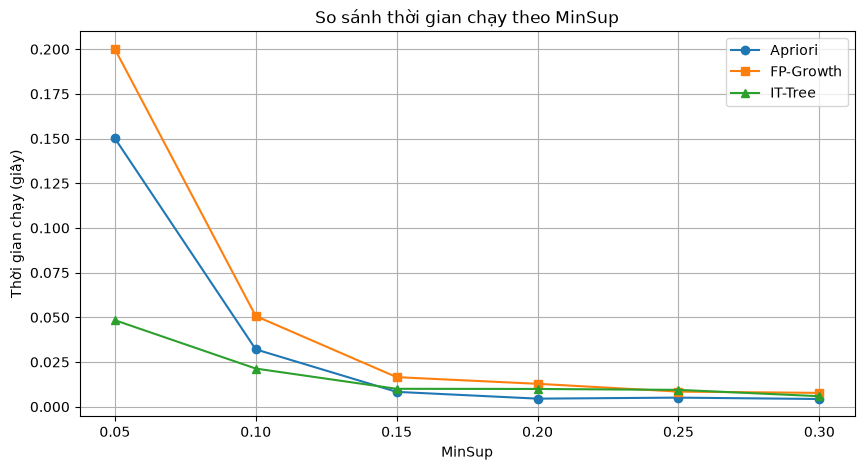

BẢNG THỜI GIAN CHẠY THEO TỪNG MINSUP


,MinSup,Apriori_Time,FP_Growth_Time,IT_Tree_Time
0,0.05,0.1502,0.2001,0.0484
1,0.10,0.0321,0.0507,0.0213
2,0.15,0.0083,0.0165,0.0100
3,0.20,0.0045,0.0128,0.0099
4,0.25,0.0051,0.0084,0.0094
5,0.30,0.0043,0.0077,0.0059


In [10]:
# BIỂU ĐỒ THỜI GIAN CHẠY CỦA 3 THUẬT TOÁN

plt.figure(figsize=(10, 5))

plt.plot(experiment_df["MinSup"],
         experiment_df["Apriori_Time"],
         marker="o", label="Apriori")

plt.plot(experiment_df["MinSup"],
         experiment_df["FP_Growth_Time"],
         marker="s", label="FP-Growth")

plt.plot(experiment_df["MinSup"],
         experiment_df["IT_Tree_Time"],
         marker="^", label="IT-Tree")

plt.xlabel("MinSup")
plt.ylabel("Thời gian chạy (giây)")
plt.title("So sánh thời gian chạy theo MinSup")
plt.legend()
plt.grid(True)
plt.show()

# BẢNG THỜI GIAN CHẠY (4 CHỮ SỐ THẬP PHÂN)

print("BẢNG THỜI GIAN CHẠY THEO TỪNG MINSUP")

bang_thoi_gian = experiment_df[
    ["MinSup", "Apriori_Time",
     "FP_Growth_Time", "IT_Tree_Time"]
]

display(bang_thoi_gian.round(4))

In [11]:
# HÀM KHAI PHÁ TẬP PHỔ BIẾN

def mine_itemsets(minsup):

    # Chạy Apriori với ngưỡng MinSup
    frequent_itemsets = apriori(
        df_encoded,
        min_support=minsup,
        use_colnames=True
    )

    return frequent_itemsets


# Kiểm tra hàm
itemsets_demo = mine_itemsets(0.1)

print("MinSup: 0.1")
print("Số tập phổ biến:", len(itemsets_demo))

display(itemsets_demo.head(10))

MinSup: 0.1
Số tập phổ biến: 2558


,support,itemsets
0,0.888,frozenset({breakfast_Breakfast_No})
1,0.112,frozenset({breakfast_Breakfast_Yes})
2,0.608,frozenset({eating_out_Low})
3,0.296,frozenset({eating_out_Medium})
4,0.504,frozenset({fruit_day_High})
5,0.456,frozenset({fruit_day_Medium})
6,0.424,frozenset({veggies_day_High})
7,0.112,frozenset({veggies_day_Low})
8,0.464,frozenset({veggies_day_Medium})
9,0.160,frozenset({calories_day_Low})


LƯU FILE KẾT QUẢ TỪNG THUẬT TOÁN VÀ BIỂU ĐỒ TRỰC QUAN

In [12]:
frequent_itemsets_ap.to_csv("../Data/frequent_itemsets_apriori.csv", index=False)
frequent_itemsets_fp.to_csv("../Data/frequent_itemsets_fpgrowth.csv", index=False)
frequent_itemsets_it.to_csv("../Data/frequent_itemsets_ittree.csv", index=False)
experiment_df.to_csv("../Data/minsup_experiment_3_algorithms.csv", index=False)
print("Đã lưu 4 file CSV kết quả vào thư mục Data thành công!")


Đã lưu 4 file CSV kết quả vào thư mục Data thành công!



Nguồn tham khảo : [mlxtend Apriori](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/apriori/), [mlxtend FP-Growth](https://rasbt.github.io/mlxtend/user_guide/frequent_patterns/fpgrowth/).

SINH LUẬT KẾT HỢP TỪ TẬP PHỔ BIẾN

In [13]:
from mlxtend.frequent_patterns import association_rules

# 1. Sinh luật kết hợp từ tập phổ biến (dùng kết quả FP-Growth hoặc Apriori ở minsup=0.1)
# frequent_itemsets_fp đã được tính ở các cell trước
rules = association_rules(
    frequent_itemsets_fp, 
    metric="confidence", 
    min_threshold=0.5
)

# 2. Thêm cột độ dài của tiền đề và hệ quả để dễ lọc
rules["antecedent_len"] = rules["antecedents"].apply(lambda x: len(x))
rules["consequent_len"] = rules["consequents"].apply(lambda x: len(x))

# 3. Lọc các luật có ý nghĩa thống kê thực sự (Lift > 1.0)
meaningful_rules = rules[rules["lift"] > 1.0].copy()

print(f"Tổng số luật sinh ra với Min Confidence >= 0.5: {len(rules)}")
print(f"Số luật có ý nghĩa (Lift > 1.0): {len(meaningful_rules)}")

# Hiển thị 10 luật có Lift cao nhất
meaningful_rules.sort_values(by="lift", ascending=False).head(10)[
    ["antecedents", "consequents", "support", "confidence", "lift"]
]


Tổng số luật sinh ra với Min Confidence >= 0.5: 15634
Số luật có ý nghĩa (Lift > 1.0): 14324


,antecedents,consequents,support,confidence,lift
4340,"frozenset({thai_food_High, ethnic_food_High, e...","frozenset({italian_food_High, greek_food_High,...",0.128,0.842105,4.385965
4325,"frozenset({italian_food_High, greek_food_High,...","frozenset({thai_food_High, ethnic_food_High, e...",0.128,0.666667,4.385965
4332,"frozenset({eating_out_Low, greek_food_High, in...","frozenset({thai_food_High, ethnic_food_High, i...",0.128,0.941176,4.357298
4333,"frozenset({thai_food_High, ethnic_food_High, i...","frozenset({eating_out_Low, greek_food_High, in...",0.128,0.592593,4.357298
4627,"frozenset({thai_food_High, ethnic_food_High, i...","frozenset({indian_food_High, greek_food_High, ...",0.120,0.555556,4.340278
4632,"frozenset({italian_food_High, greek_food_High,...","frozenset({thai_food_High, ethnic_food_High, e...",0.120,0.625000,4.340278
4588,"frozenset({thai_food_High, ethnic_food_High, e...","frozenset({italian_food_High, greek_food_High,...",0.120,0.833333,4.340278
4593,"frozenset({indian_food_High, greek_food_High, ...","frozenset({thai_food_High, ethnic_food_High, i...",0.120,0.937500,4.340278
4621,"frozenset({thai_food_High, ethnic_food_High, e...","frozenset({italian_food_High, greek_food_High,...",0.120,0.789474,4.290618
4603,"frozenset({italian_food_High, greek_food_High,...","frozenset({thai_food_High, ethnic_food_High, e...",0.120,0.652174,4.290618


ĐÁNH GIÁ VÀ SO SÁNH

In [14]:
conf_thresholds = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
sensitivity_results = []
for conf in conf_thresholds:
    temp_rules = association_rules(frequent_itemsets_fp, metric="confidence", min_threshold=conf)
    # Lọc luật có ý nghĩa
    meaningful = temp_rules[temp_rules["lift"] > 1.0]
    
    sensitivity_results.append({
        "Min_Confidence": conf,
        "Total_Rules": len(temp_rules),
        "Meaningful_Rules (Lift > 1)": len(meaningful),
        "Avg_Lift": meaningful["lift"].mean() if len(meaningful) > 0 else 0,
        "Max_Lift": meaningful["lift"].max() if len(meaningful) > 0 else 0
    })
df_sensitivity = pd.DataFrame(sensitivity_results)
print("BẢNG KHẢO SÁT ĐỘ NHẠY THAM SỐ MIN_CONFIDENCE:")
display(df_sensitivity)


BẢNG KHẢO SÁT ĐỘ NHẠY THAM SỐ MIN_CONFIDENCE:


,Min_Confidence,Total_Rules,Meaningful_Rules (Lift > 1),Avg_Lift,Max_Lift
0,0.3,27046,24317,1.725504,4.385965
1,0.4,20494,18610,1.771718,4.385965
2,0.5,15634,14324,1.801569,4.385965
3,0.6,10431,9561,1.827069,4.385965
4,0.7,6299,5645,1.866248,4.385965
5,0.8,3601,3348,1.804738,4.385965


DIỄN GIẢI TRI THỨC VÀ ĐỀ XUẤT ỨNG DỤNG THỰC TIỄN
 
 Mục tiêu bước diễn giải
- Trích xuất các tập phổ biến có độ dài từ 2 trở lên (kết hợp giữa Thói quen ăn uống và Sở thích thực phẩm).
- Loại bỏ các tập đơn lẻ hoặc hiển nhiên để chọn lọc các mẫu hành vi tiêu biểu nhất của sinh viên.
- Chuyển đổi các con số thống kê thành nhận xét dễ hiểu và đề xuất giải pháp thực tế hỗ trợ quyết định kinh doanh/căn tin trường học.


In [15]:
# 1. Thêm cột độ dài tập itemset
frequent_itemsets_fp["length"] = frequent_itemsets_fp["itemsets"].apply(lambda x: len(x))

# 2. Lọc các tập có độ dài >= 2 và chứa các thuộc tính quan trọng liên quan đến bài toán
# (Chỉ lấy các tập kết hợp từ 2 thói quen trở lên để tìm mối liên hệ)
multi_itemsets = frequent_itemsets_fp[frequent_itemsets_fp["length"] >= 2].copy()

# 3. Tính số lượng sinh viên thực tế tương ứng với Support (Tổng sinh viên = 122)
total_students = len(df_encoded)
multi_itemsets["student_count"] = (multi_itemsets["support"] * total_students).round().astype(int)

# 4. Sắp xếp theo Support giảm dần và lấy Top 10 mẫu phổ biến nhất
top_patterns = multi_itemsets.sort_values(by="support", ascending=False).head(10)

# Hàm định dạng hiển thị tên các item cho gọn gàng
def display_itemset(item_set):
    return " + ".join(list(item_set))

top_patterns["Tập hành vi / sở thích"] = top_patterns["itemsets"].apply(display_itemset)

print("=== BẢNG TOP CÁC MẪU HÀNH VI TIÊU BIỂU ĐƯỢC PHÁT HIỆN ===")
display_df = top_patterns[["Tập hành vi / sở thích", "support", "student_count"]].rename(
    columns={"support": "Tỷ lệ ủng hộ (Support)", "student_count": "Số sinh viên (trên 122)"}
)
display_df["Tỷ lệ ủng hộ (Support)"] = (display_df["Tỷ lệ ủng hộ (Support)"] * 100).round(2).astype(str) + "%"

display(display_df.reset_index(drop=True))


=== BẢNG TOP CÁC MẪU HÀNH VI TIÊU BIỂU ĐƯỢC PHÁT HIỆN ===


,Tập hành vi / sở thích,Tỷ lệ ủng hộ (Support),Số sinh viên (trên 122)
0,italian_food_High + breakfast_Breakfast_No,72.0%,90
1,healthy_feeling_High + breakfast_Breakfast_No,56.0%,70
2,eating_out_Low + breakfast_Breakfast_No,53.6%,67
3,fruit_day_High + breakfast_Breakfast_No,48.8%,61
4,cook_Medium + breakfast_Breakfast_No,48.0%,60
5,italian_food_High + healthy_feeling_High,47.2%,59
6,italian_food_High + eating_out_Low,47.2%,59
7,calories_day_Medium + breakfast_Breakfast_No,46.4%,58
8,nutritional_check_Medium + breakfast_Breakfast_No,45.6%,57
9,ethnic_food_Medium + breakfast_Breakfast_No,44.8%,56
